In [150]:
#Import libraries that will be used throughout the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import (mutual_info_score, accuracy_score,
precision_score, recall_score, f1_score, roc_curve, auc, roc_auc_score,confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from IPython.display import display
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
pd.set_option('display.max_columns', None)

In [151]:
#load dataset
df = pd.read_csv("credit_card_fraud_2026.csv")

In [152]:
#check the data
df.head()

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,22.35,39,25,1080.71,False,False,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,35.28,47,33,4463.72,True,False,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,9.82,51,59,366.25,False,True,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,19.72,48,28,1345.29,True,False,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,17.68,43,36,4192.59,False,False,False,False,0,3.9,2,4,False,32.7,0,0


In [153]:
df.shape

(20000, 26)

In [154]:
#check for missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_id                20000 non-null  int64  
 1   amount_usd                    20000 non-null  float64
 2   merchant_category             20000 non-null  str    
 3   card_type                     20000 non-null  str    
 4   auth_method                   20000 non-null  str    
 5   channel                       20000 non-null  str    
 6   device_type                   20000 non-null  str    
 7   is_foreign_transaction        20000 non-null  bool   
 8   hours_since_last_txn          20000 non-null  float64
 9   txn_count_last_24h            20000 non-null  int64  
 10  distance_from_home_km         20000 non-null  float64
 11  card_age_months               20000 non-null  int64  
 12  customer_age                  20000 non-null  int64  
 13  account_bala

In [155]:
#Check for atypical values
df.describe()

,transaction_id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,132.424597,8.950827,3.191650,22.139525,46.937550,49.669400,3316.662598,0.181300,19.807735,11.533650,2.998750,37.400390,0.281250,0.016950
std,5773.647028,256.963666,8.838745,1.779544,22.120960,6.768577,18.494032,4350.720948,0.422302,12.366301,6.925335,2.004956,17.061415,0.529209,0.129087
min,1.000000,1.000000,0.010000,0.000000,0.000000,22.000000,18.000000,52.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5000.750000,26.235000,2.590000,2.000000,6.337500,42.000000,34.000000,1019.140000,0.000000,10.700000,6.000000,1.000000,25.600000,0.000000,0.000000
50%,10000.500000,57.510000,6.210000,3.000000,15.505000,47.000000,50.000000,2007.685000,0.000000,18.800000,12.000000,3.000000,35.700000,0.000000,0.000000
75%,15000.250000,131.752500,12.432500,4.000000,30.820000,51.000000,66.000000,3944.120000,0.000000,27.600000,18.000000,5.000000,47.300000,0.000000,0.000000
max,20000.000000,6872.690000,87.050000,12.000000,216.190000,74.000000,81.000000,127125.860000,3.000000,74.400000,23.000000,6.000000,100.000000,4.000000,1.000000


In [156]:
#There are no atypical values in the dataset. Next step is separating categorical and numerical values
#Also check the imbalance in the dataset

In [157]:
df['is_fraud'].mean()

np.float64(0.01695)

In [158]:
df.head()

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,22.35,39,25,1080.71,False,False,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,35.28,47,33,4463.72,True,False,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,9.82,51,59,366.25,False,True,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,19.72,48,28,1345.29,True,False,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,17.68,43,36,4192.59,False,False,False,False,0,3.9,2,4,False,32.7,0,0


In [159]:
df['day_of_week'] = df['day_of_week'].map({0: 'Sunday',
                                          1: 'Monday',
                                          2: 'Tuesday',
                                          3: 'Wednesday',
                                          4: 'Thursday',
                                          5: 'Friday',
                                          6: 'Saturday'})

In [160]:
df['day_of_week'].unique()

<StringArray>
['Wednesday', 'Thursday', 'Sunday', 'Saturday', 'Monday', 'Friday', 'Tuesday']
Length: 7, dtype: str

In [161]:
categorical = ['merchant_category','card_type','auth_method','channel','device_type','is_foreign_transaction',
              'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch','time_of_day_hour','day_of_week',
              'is_ai_generated_scam_attempt']
numerical = ['amount_usd','hours_since_last_txn','txn_count_last_24h','distance_from_home_km','card_age_months',
            'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'merchant_risk_score','prior_disputes']

In [162]:
df2 = df.drop(['transaction_id'], axis=1)

In [163]:
df_full_train, df_test = train_test_split(df2, test_size=0.2, random_state=1, stratify = df2['is_fraud'])
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1, stratify = df_full_train['is_fraud'])

In [164]:
y_train = df_train['is_fraud']
y_val = df_val['is_fraud']

In [165]:
#This is the general method for mutual information for all varibales
X=df_train.drop(columns=['is_fraud']).copy().reset_index(drop=True)
y=df_train['is_fraud']

bool_cols = X.select_dtypes(include=['bool']).columns
X[bool_cols] = X[bool_cols].astype(int)
str_cols = X.select_dtypes(include=['object', 'string']).columns
if len(str_cols) > 0:
    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    X[str_cols] = encoder.fit_transform(X[str_cols].astype(str))
discrete_mask = []
for col in X.columns:
    if col in bool_cols or col in str_cols:
        discrete_mask.append(True)
    elif X[col].dtype.name.startswith('int'):
        discrete_mask.append(X[col].nunique() < 50)
    else:
        discrete_mask.append(False)

In [166]:
def calculate_mi(series):
    return mutual_info_score(series, df_train['is_fraud'])

df_mi = df_train[categorical].apply(calculate_mi)
df_mi = df_mi.sort_values(ascending=False).to_frame(name='MI')

display(df_mi)

,MI
ip_country_mismatch,0.004839
billing_shipping_mismatch,0.002873
auth_method,0.002669
time_of_day_hour,0.002625
is_new_merchant,0.002476
is_foreign_transaction,0.002307
merchant_category,0.002137
used_vpn,0.001529
is_ai_generated_scam_attempt,0.001319
device_type,0.000396


In [167]:
mi_scores = mutual_info_classif(
    X, 
    y, 
    discrete_features=discrete_mask, 
    random_state=1
)
mi_ranking = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)
print(mi_ranking)

cvv_retry_count                 0.007430
merchant_risk_score             0.004945
ip_country_mismatch             0.004839
velocity_score                  0.004549
billing_shipping_mismatch       0.002873
auth_method                     0.002669
time_of_day_hour                0.002625
is_new_merchant                 0.002476
txn_count_last_24h              0.002470
customer_age                    0.002370
is_foreign_transaction          0.002307
merchant_category               0.002137
distance_from_home_km           0.002134
used_vpn                        0.001529
is_ai_generated_scam_attempt    0.001319
account_balance_usd             0.000893
prior_disputes                  0.000433
device_type                     0.000396
amount_usd                      0.000388
channel                         0.000337
card_age_months                 0.000309
card_type                       0.000209
day_of_week                     0.000120
hours_since_last_txn            0.000041
dtype: float64


In [168]:
#Now let's see for the numerical variables

In [169]:
dfcorr = df_train[numerical].corrwith(df_train['is_fraud']).to_frame('correlation')
dfcorr
dfcorr.sort_values(by='correlation',ascending=False)

,correlation
cvv_retry_count,0.153512
velocity_score,0.100471
merchant_risk_score,0.100145
txn_count_last_24h,0.063561
amount_usd,0.026004
customer_age,0.021298
prior_disputes,0.018850
account_balance_usd,0.001334
card_age_months,0.000827
distance_from_home_km,-0.001520


In [170]:
global_mean = df_train['is_fraud'].mean()
global_mean

for col in categorical:
    df_group = df_train.groupby(by=col)['is_fraud'].agg(['mean'])
    df_group['diff'] = df_group['mean'] - global_mean
    df_group['risk'] = df_group['mean'] / global_mean
    display(df_group)

,mean,diff,risk
merchant_category,,,
Crypto Exchange,0.042424,0.025508,2.507837
Electronics,0.020886,0.003969,1.234614
Fuel,0.011765,-0.005152,0.695451
Gaming,0.032206,0.015289,1.903810
Gift Cards,0.043597,0.026680,2.577147
Groceries,0.015244,-0.001673,0.901117
Healthcare,0.014589,-0.002328,0.862396
Online Retail,0.007357,-0.009560,0.434870
Restaurants,0.014360,-0.002556,0.848886


,mean,diff,risk
card_type,,,
Amex,0.021672,0.004755,1.281093
Discover,0.020270,0.003354,1.198243
Mastercard,0.015273,-0.001644,0.902832
RuPay,0.011429,-0.005488,0.675581
Visa,0.017744,0.000828,1.048935


,mean,diff,risk
auth_method,,,
3D Secure,0.016091,-0.000826,0.951168
Biometric,0.005059,-0.011858,0.299055
No Authentication,0.041144,0.024227,2.432137
OTP,0.018468,0.001551,1.091696
PIN,0.010770,-0.006147,0.636641


,mean,diff,risk
channel,,,
ATM,0.020382,0.003465,1.204857
Contactless,0.012884,-0.004033,0.761618
In-App,0.015215,-0.001702,0.899415
Online,0.020986,0.004069,1.240543
POS,0.014407,-0.002510,0.851617


,mean,diff,risk
device_type,,,
ATM Machine,0.016556,-0.000360,0.978697
Android Phone,0.017633,0.000716,1.042345
Mac,0.025316,0.008400,1.496539
POS Terminal,0.016349,-0.000568,0.966430
Smart Watch,0.016807,-0.000110,0.993501
Tablet,0.023460,0.006544,1.386822
Windows PC,0.010404,-0.006513,0.615010
iPhone,0.016309,-0.000608,0.964059


,mean,diff,risk
is_foreign_transaction,,,
False,0.014062,-0.002855,0.831248
True,0.058901,0.041984,3.481804


... (3 outputs left out)

,mean,diff,risk
billing_shipping_mismatch,,,
False,0.014118,-0.002799,0.834541
True,0.078095,0.061179,4.616467


,mean,diff,risk
time_of_day_hour,,,
0,0.020492,0.003575,1.211338
1,0.019231,0.002314,1.136794
2,0.037255,0.020338,2.202260
3,0.035124,0.018207,2.076294
4,0.022965,0.006048,1.357508
5,0.040323,0.023406,2.383601
6,0.010000,-0.006917,0.591133
7,0.006048,-0.010868,0.357540
8,0.015251,-0.001666,0.901510


,mean,diff,risk
day_of_week,,,
Friday,0.015394,-0.001523,0.909974
Monday,0.016628,-0.000288,0.982962
Saturday,0.019166,0.002249,1.132949
Sunday,0.017029,0.000112,1.006627
Thursday,0.013450,-0.003466,0.795091
Tuesday,0.016929,0.000013,1.000751
Wednesday,0.019796,0.002879,1.170209


,mean,diff,risk
is_ai_generated_scam_attempt,,,
False,0.015691,-0.001225,0.927562
True,0.085714,0.068798,5.066854


In [171]:
#Instead of using DictVectorizer, ColumnTransformer will be used

In [172]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)
    ]
)
X_train_final = preprocessor.fit_transform(df_train)
X_val_final = preprocessor.transform(df_val)

df_train_processed = pd.DataFrame(
    X_train_final, 
    columns=preprocessor.get_feature_names_out(),
    index=df_train.index
)

In [173]:
df_train_processed.head()

,num__amount_usd,num__hours_since_last_txn,num__txn_count_last_24h,num__distance_from_home_km,num__card_age_months,num__customer_age,num__account_balance_usd,num__cvv_retry_count,num__velocity_score,num__merchant_risk_score,num__prior_disputes,cat__merchant_category_Crypto Exchange,cat__merchant_category_Electronics,cat__merchant_category_Fuel,cat__merchant_category_Gaming,cat__merchant_category_Gift Cards,cat__merchant_category_Groceries,cat__merchant_category_Healthcare,cat__merchant_category_Online Retail,cat__merchant_category_Restaurants,cat__merchant_category_Streaming,cat__merchant_category_Travel,cat__merchant_category_Utilities,cat__card_type_Amex,cat__card_type_Discover,cat__card_type_Mastercard,cat__card_type_RuPay,cat__card_type_Visa,cat__auth_method_3D Secure,cat__auth_method_Biometric,cat__auth_method_No Authentication,cat__auth_method_OTP,cat__auth_method_PIN,cat__channel_ATM,cat__channel_Contactless,cat__channel_In-App,cat__channel_Online,cat__channel_POS,cat__device_type_ATM Machine,cat__device_type_Android Phone,cat__device_type_Mac,cat__device_type_POS Terminal,cat__device_type_Smart Watch,cat__device_type_Tablet,cat__device_type_Windows PC,cat__device_type_iPhone,cat__is_foreign_transaction_False,cat__is_foreign_transaction_True,cat__is_new_merchant_False,cat__is_new_merchant_True,cat__used_vpn_False,cat__used_vpn_True,cat__ip_country_mismatch_False,cat__ip_country_mismatch_True,cat__billing_shipping_mismatch_False,cat__billing_shipping_mismatch_True,cat__time_of_day_hour_0,cat__time_of_day_hour_1,cat__time_of_day_hour_2,cat__time_of_day_hour_3,cat__time_of_day_hour_4,cat__time_of_day_hour_5,cat__time_of_day_hour_6,cat__time_of_day_hour_7,cat__time_of_day_hour_8,cat__time_of_day_hour_9,cat__time_of_day_hour_10,cat__time_of_day_hour_11,cat__time_of_day_hour_12,cat__time_of_day_hour_13,cat__time_of_day_hour_14,cat__time_of_day_hour_15,cat__time_of_day_hour_16,cat__time_of_day_hour_17,cat__time_of_day_hour_18,cat__time_of_day_hour_19,cat__time_of_day_hour_20,cat__time_of_day_hour_21,cat__time_of_day_hour_22,cat__time_of_day_hour_23,cat__day_of_week_Friday,cat__day_of_week_Monday,cat__day_of_week_Saturday,cat__day_of_week_Sunday,cat__day_of_week_Thursday,cat__day_of_week_Tuesday,cat__day_of_week_Wednesday,cat__is_ai_generated_scam_attempt_False,cat__is_ai_generated_scam_attempt_True
3316,-0.033973,0.068089,1.572599,-0.984379,0.754345,-0.139226,-0.313952,-0.426191,1.259522,0.294895,-0.527528,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
17512,-0.293877,0.294675,-0.113483,-0.097648,-1.177238,1.050583,-0.339192,-0.426191,0.396750,-0.866239,-0.527528,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
17724,1.401967,-0.950979,-0.113483,-0.554961,1.200095,1.158748,0.582132,-0.426191,1.186952,-0.356762,-0.527528,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3123,-0.275193,-0.635580,-1.237537,-0.578742,1.645845,1.320995,-0.512273,-0.426191,-1.361047,0.129019,-0.527528,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.

In [174]:
#Let's try a logistic regression
model = LogisticRegression(solver='liblinear', random_state=1)
model.fit(X_train_final, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_

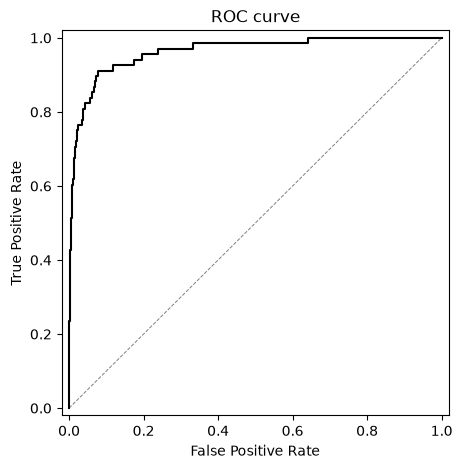

In [175]:
#Let's see the ROC curve and AUC value
fpr, tpr, thresholds = roc_curve(y_val, model.predict_proba(X_val_final)[:,1])
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, color='black')
plt.plot([0, 1], [0, 1], color='black', lw=0.7, linestyle='dashed', alpha=0.5)

plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC curve')

plt.show()

In [176]:
auc_global = roc_auc_score(y_val, model.predict_proba(X_val_final)[:,1])
auc_global

0.9624424032074682

In [177]:
accuracy_score(y_val, model.predict(X_val_final))

0.98525

In [178]:
#Let's define the threeshold. The dataset is imbalanced so accuracy won't do any good
#Precision, recall and f1score for different threesholds
thresholds = np.linspace(0, 1, 21)
recalls =[]
precisions = []
f1scores = []
for t in thresholds:
    y_pred = model.predict_proba(X_val_final)[:,1] >= t
    prec = precision_score(y_val, y_pred)
    precisions.append(prec)
    rec = recall_score(y_val, y_pred)
    recalls.append(rec)
    f1s = f1_score(y_val, y_pred)
    f1scores.append(f1s)
    print('%0.2f %0.3f %0.3f %0.3f' % (t, prec, rec, f1s))

0.00 0.017 1.000 0.033
0.05 0.236 0.824 0.367
0.10 0.368 0.721 0.488
0.15 0.449 0.647 0.530
0.20 0.500 0.618 0.553
0.25 0.569 0.544 0.556
0.30 0.596 0.456 0.517
0.35 0.674 0.426 0.523
0.40 0.686 0.353 0.466
0.45 0.724 0.309 0.433
0.50 0.696 0.235 0.352
0.55 0.882 0.221 0.353
0.60 0.875 0.206 0.333
0.65 0.867 0.191 0.313
0.70 0.909 0.147 0.253
0.75 0.875 0.103 0.184
0.80 0.750 0.044 0.083
0.85 1.000 0.044 0.085
0.90 1.000 0.044 0.085
0.95 1.000 0.015 0.029
1.00 0.000 0.000 0.000


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


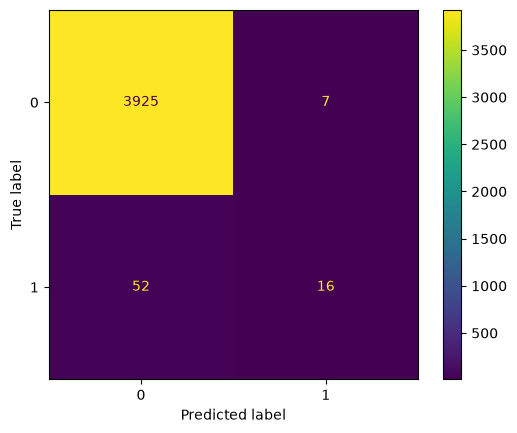

In [179]:
#Let's see the confusion matrix with 0.5 threeshold
def conf_matrix_plot(model, x_data, y_data):
    model_pred = model.predict(x_data)
    cm = confusion_matrix(y_data, model_pred, labels=model.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
    display_labels=model.classes_)
    disp.plot(values_format="")


conf_matrix_plot(model, X_val_final, y_val)

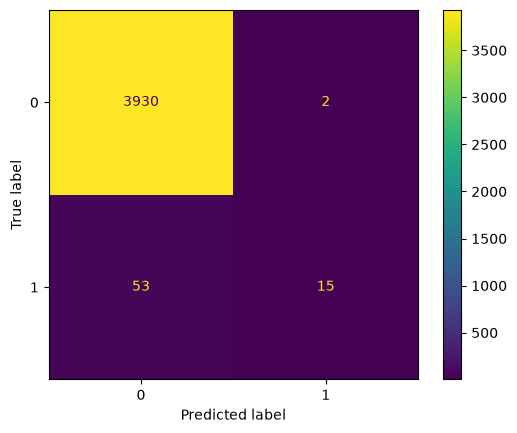

In [180]:
def conf_matrix_plot(model, x_data, y_data):
    model_pred = model.predict_proba(x_data)[:,1]>=0.55
    cm = confusion_matrix(y_data, model_pred, labels=model.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
    display_labels=model.classes_)
    disp.plot(values_format="")


conf_matrix_plot(model, X_val_final, y_val)

In [181]:
nfolds = 5
kfold = StratifiedKFold(n_splits=nfolds, shuffle=True, random_state=1)
y_full_train = df_full_train['is_fraud'].values


for C in [0.001, 0.01, 0.1, 0.5, 1, 10]:
    recalls =[]
    precisions = []
    f1scores = []

    for train_idx, val_idx in kfold.split(df_full_train, y_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
        X_train_final = preprocessor.fit_transform(df_train)
        X_val_final = preprocessor.transform(df_val)

        y_train = y_full_train[train_idx]
        y_val = y_full_train[val_idx]

        model = LogisticRegression(solver='liblinear', C=C, random_state=1)
        model.fit(X_train_final, y_train)
        
        y_pred = model.predict_proba(X_val_final)[:,1] >= 0.55

        prec = precision_score(y_val, y_pred, zero_division=0)
        rec = recall_score(y_val, y_pred,zero_division=0)
        f1s = f1_score(y_val, y_pred,zero_division=0)
        precisions.append(prec)
        recalls.append(rec)
        f1scores.append(f1s)
        

    print(
        f"C={C:<6} | "
        f"Prec: {np.mean(precisions):.3f} (±{np.std(precisions):.3f}) | "
        f"Rec: {np.mean(recalls):.3f} (±{np.std(recalls):.3f}) | "
        f"F1: {np.mean(f1scores):.3f} (±{np.std(f1scores):.3f})"
    )

C=0.001  | Prec: 0.000 (±0.000) | Rec: 0.000 (±0.000) | F1: 0.000 (±0.000)
C=0.01   | Prec: 0.800 (±0.400) | Rec: 0.015 (±0.007) | F1: 0.029 (±0.014)
C=0.1    | Prec: 0.804 (±0.143) | Rec: 0.140 (±0.041) | F1: 0.237 (±0.064)
C=0.5    | Prec: 0.714 (±0.145) | Rec: 0.217 (±0.060) | F1: 0.329 (±0.077)
C=1      | Prec: 0.707 (±0.136) | Rec: 0.225 (±0.051) | F1: 0.338 (±0.066)
C=10     | Prec: 0.631 (±0.127) | Rec: 0.236 (±0.063) | F1: 0.341 (±0.081)
